# Detección de anomalías en las capturas pesqueras argentinas

**Aprendizaje Automático – Grupo 12**

Integrantes:
- Bernal, Alejandro Matias
- Paredes, Sebastian Pablo
- Rodrigues, David Ezequiel
- Barnetche, Iñaki Francisco

---

## 1. Introducción

### Dominio de aplicación
La pesca marítima es una actividad económica relevante para Argentina. Cada mes se registran desembarques en los puertos del litoral marítimo, con especies, flotas y volúmenes muy distintos entre sí. Estos registros son publicados como datos abiertos por el Ministerio de Agricultura, Ganadería y Pesca (MAGyP).

Las capturas varían mucho según la especie, el puerto, el tipo de flota y la época del año. Por eso, un valor alto o bajo no indica por sí solo algo fuera de lo normal: lo habitual para una especie en un puerto puede ser excepcional para otra.

### Objetivo del modelo
Planteamos el problema como una clasificación con tres clases. Para cada combinación especie–puerto, y usando solo la información disponible hasta el mes *t−1*, el modelo predice si la captura del mes *t* será:

- `normal`: dentro de lo esperable para esa especie, ese puerto y esa época del año.
- `caida`: anomalía por déficit; la captura queda muy por debajo de su comportamiento histórico.
- `aumento`: anomalía por exceso; la captura queda muy por encima de su comportamiento histórico.

El modelo no explica por qué ocurre la anomalía. Su función es señalar esos casos con anticipación para analizarlos después.

### Elección de tres clases
En la entrega anterior la variable objetivo era binaria (normal / anómala) y el sentido de la anomalía se guardaba aparte. Siguiendo la recomendación de la cátedra, ahora el sentido forma parte de la variable objetivo, porque una caída y un aumento tienen causas y consecuencias distintas y llevan a acciones distintas.

- Ventajas: la alerta indica qué acción tomar, y el modelo puede aprovechar que las predictoras se comportan distinto antes de una caída que antes de un aumento (sección 4.4). Con una etiqueta binaria esas diferencias se mezclan.
- Desventajas: cada clase anómala tiene menos ejemplos, lo que aumenta el desbalance. Se compensa ponderando las clases y evaluando cada clase por separado (sección 7).

### Beneficios esperados

| Beneficio | Detección sin diferenciar el sentido | Detección de caída y aumento por separado |
|---|---|---|
| Anticipar cambios en la captura de una especie | Avisa que el mes será inusual | Indica si habrá faltante (caída) o exceso (aumento) de materia prima |
| Planificar producción, almacenamiento y transporte | No indica si hay que aumentar o reducir la capacidad | Indica el sentido del ajuste: reducir turnos y fletes ante una caída, reforzar frío y transporte ante un aumento |
| Detectar cambios en la actividad de los puertos | Identifica qué puertos cambiaron | Distingue un puerto que pierde actividad de uno que la gana |
| Orientar estudios sobre presión pesquera o cambios ambientales | Señala qué series revisar | Un aumento sostenido sugiere mayor presión pesquera; una caída sostenida, menor disponibilidad del recurso o una veda |
| Identificar registros que podrían ser incorrectos | Es suficiente: cualquier valor fuera de lo habitual se revisa | Orienta la revisión: un aumento extremo puede ser un error de carga y una caída a cero, un registro faltante |

**Utilidad de la detección sin diferenciar el sentido.** Aun sin conocer el sentido, la detección sirve como primer filtro: reduce cientos de series a unas pocas que hay que revisar. Para controlar la calidad de los datos alcanza con saber que un valor es inusual. Para el resto de los beneficios hace falta conocer el sentido, y por eso usamos tres clases. Además, el modelo de tres clases también permite dar la alerta sin sentido, sumando las probabilidades de caída y de aumento (sección 7).

### Técnicas no vistas en la asignatura

| Técnica | Uso | Sección |
|---|---|---|
| Transformación `log1p` | Reducir la asimetría de la captura | 3.3 |
| Mediana, MAD y puntaje *z* robusto | Definir la variable objetivo | 4.1 |
| Codificación del mes con seno y coseno | Representar el mes como variable cíclica | 4.3 |
| PR-AUC | Métrica para clases desbalanceadas | 7 |
| Importancia por permutación | Ver qué variables usa el modelo | 7 |

## 2. Carga de datos

Fuente: [Datos Abiertos MAGyP – Desembarques de pesca marítima](https://datos.magyp.gob.ar/dataset/http-www-magyp-gob-ar-sitio-areas-pesca-maritima-desembarques). Recurso principal: desembarques 2010–2018.

La celda de carga lee el archivo si ya está en el entorno; si no, lo descarga desde `DATA_URL`, y si no hay URL, pide subirlo manualmente (Colab).

In [1]:
# Importación de librerías y configuración general
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 250)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 4.5)
RANDOM_STATE = 42

In [2]:
# Carga del dataset y normalización de los nombres de columnas
ARCHIVO = "desembarques_2010_2018.csv"
DATA_URL = "https://datos.magyp.gob.ar/dataset/e2f12522-4dea-495e-877a-b6d2737ae6bf/resource/1996a5ec-7075-4062-9a79-05868fc2a2e2/download/captura-puerto-flota-2010-2018.csv"

def leer_csv(ruta):
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(ruta, encoding=enc, sep=None, engine="python")
        except UnicodeDecodeError:
            continue
    raise ValueError("No se pudo leer el archivo")

if os.path.exists(ARCHIVO):
    df_raw = leer_csv(ARCHIVO)
elif DATA_URL:
    df_raw = leer_csv(DATA_URL)
else:
    from google.colab import files
    subido = files.upload()
    ARCHIVO = next(iter(subido))
    df_raw = leer_csv(ARCHIVO)

df_raw.columns = (df_raw.columns.str.strip().str.lower()
                  .str.replace(" ", "_").str.replace("í", "i").str.replace("ó", "o"))
print("Dimensiones:", df_raw.shape)
df_raw.head()

Dimensiones: (41340, 13)


,fecha,flota,puerto,provincia,provincia_id,departamento,departamento_id,latitud,longitud,categoria,especie,especie_agrupada,captura
0,2010-01,Costeros,Caleta Cordova,Chubut,26,Escalante,26021,-45.75,-67.38,Peces,Merluza hubbsi,Merluza hubbsi S41,386114
1,2010-01,Costeros,Caleta Cordova,Chubut,26,Escalante,26021,-45.75,-67.38,Peces,Pez gallo,otras especies,4367
2,2010-01,Costeros,Caleta Cordova,Chubut,26,Escalante,26021,-45.75,-67.38,Peces,Rayas nep,Rayas (sin V. Cost),13
3,2010-01,Rada o ría,Caleta Cordova,Chubut,26,Escalante,26021,-45.75,-67.38,Crustáceos,Centolla,Centolla,48218
4,2010-01,Rada o ría,Caleta Cordova,Chubut,26,Escalante,26021,-45.75,-67.38,Peces,Merluza hubbsi,Merluza hubbsi S41,935


## 3. Análisis Exploratorio de Datos (EDA)

### 3.1 Estructura general

In [3]:
# Tipos de datos y cantidad de valores no nulos de cada variable
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 41340 entries, 0 to 41339
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   fecha             41340 non-null  str    
 1   flota             41340 non-null  str    
 2   puerto            41340 non-null  str    
 3   provincia         41340 non-null  str    
 4   provincia_id      41340 non-null  int64  
 5   departamento      41340 non-null  str    
 6   departamento_id   41340 non-null  int64  
 7   latitud           38960 non-null  float64
 8   longitud          38960 non-null  float64
 9   categoria         41340 non-null  str    
 10  especie           41340 non-null  str    
 11  especie_agrupada  41340 non-null  str    
 12  captura           41340 non-null  int64  
dtypes: float64(2), int64(3), str(8)
memory usage: 4.1 MB


In [4]:
# Cantidad de valores distintos de cada variable
df_raw.nunique().to_frame("unicos").T

,fecha,flota,puerto,provincia,provincia_id,departamento,departamento_id,latitud,longitud,categoria,especie,especie_agrupada,captura
unicos,108,8,23,6,6,17,18,21,21,4,89,16,19621


In [5]:
# Estadísticas descriptivas de todas las variables
df_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fecha,41340,108,2010-05,584,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flota,41340,8,Rada o ría,12329,NaN,NaN,NaN,NaN,NaN,NaN,NaN
puerto,41340,23,Mar del Plata,17744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
provincia,41340,6,Buenos Aires,28395,NaN,NaN,NaN,NaN,NaN,NaN,NaN
provincia_id,"41,340.00",NaN,NaN,NaN,21.15,26.03,6.00,6.00,6.00,26.00,99.00
departamento,41340,17,General Pueyrredon,17744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departamento_id,"41,340.00",NaN,NaN,NaN,"21,465.26","25,885.09","6,056.00","6,357.00","6,357.00","26,021.00","99,999.00"
latitud,"38,960.00",NaN,NaN,NaN,-39.98,3.74,-54.87,-40.73,-38.05,-38.05,-35.75
longitud,"38,960.00",NaN,NaN,NaN,-60.44,3.85,-68.41,-64.93,-57.54,-57.54,-56.75
categoria,41340,4,Peces,36502,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Hallazgos y acciones:**
- El dataset tiene 41.340 registros y 13 variables. La única medición es `captura` (en kg); `provincia_id` y `departamento_id` son códigos, y `latitud` y `longitud` son fijas para cada puerto.
- `fecha` está guardada como texto (año-mes). Acción: convertirla a fecha y obtener `anio` y `mes` (paso 3 del preprocesamiento).
- Cada puerto pertenece a un solo departamento y provincia, así que `provincia_id`, `departamento` y `departamento_id` repiten información de `provincia` y `puerto`. Los códigos 99 y 99999 significan «sin especificar» y solo aparecen en «otros puertos». Acción: eliminar esas tres columnas (paso 5).
- La captura mínima es 1 kg: no hay registros con captura 0. Un mes sin desembarque no aparece como fila. Acción: agregar esos meses con captura 0 (paso 8).
- Hay 89 especies y 23 puertos, que forman 719 combinaciones especie–puerto (3.7).

### 3.2 Valores faltantes y duplicados

In [6]:
# Valores faltantes por variable y registros duplicados
faltantes = pd.DataFrame({"faltantes": df_raw.isna().sum(),
                          "porcentaje": df_raw.isna().mean() * 100})
display(faltantes[faltantes.faltantes > 0])

dup_exactos = df_raw.duplicated().sum()
claves = ["fecha", "flota", "puerto", "especie"]
dup_clave = df_raw.duplicated(subset=claves).sum()
print(f"Duplicados exactos: {dup_exactos}")
print(f"Registros repetidos por clave (fecha, flota, puerto, especie): {dup_clave}")

,faltantes,porcentaje
latitud,2380,5.76
longitud,2380,5.76


Duplicados exactos: 0
Registros repetidos por clave (fecha, flota, puerto, especie): 6253


In [7]:
# Puertos con coordenadas faltantes y cantidad de coordenadas distintas registradas en cada uno
sin_coord = df_raw[df_raw.latitud.isna() | df_raw.longitud.isna()].puerto.unique()
coords_por_puerto = df_raw.groupby("puerto")[["latitud", "longitud"]].agg(lambda s: s.dropna().nunique())
display(coords_por_puerto.loc[sin_coord].rename(columns=lambda c: f"{c}_valores_distintos"))

,latitud_valores_distintos,longitud_valores_distintos
puerto,,
otros puertos Buenos Aires,0,0
otros puertos,0,0


Los faltantes de coordenadas (5,8 %) corresponden solo a dos categorías agregadas, «otros puertos» y «otros puertos Buenos Aires», que agrupan varios puertos menores y no tienen coordenadas en ningún registro. El resto de los puertos tiene coordenadas completas. El tratamiento de estas categorías se define en la sección 3.5.

No hay duplicados exactos, pero 6.253 registros (15 %) repiten la combinación fecha–flota–puerto–especie con algún otro valor distinto. No se eliminan: se suman al agregar por especie–puerto–mes (paso 7).

### 3.3 Variable `captura`

count       41,340.00
mean       165,701.49
std        906,552.07
min              1.00
1%              18.00
5%              40.00
25%            420.00
50%          2,811.00
75%         23,125.75
95%        560,790.90
99%      4,006,486.79
max     25,232,438.00
Name: captura, dtype: float64

Capturas = 0: 0 | Capturas < 0: 0
Asimetría: 10.75


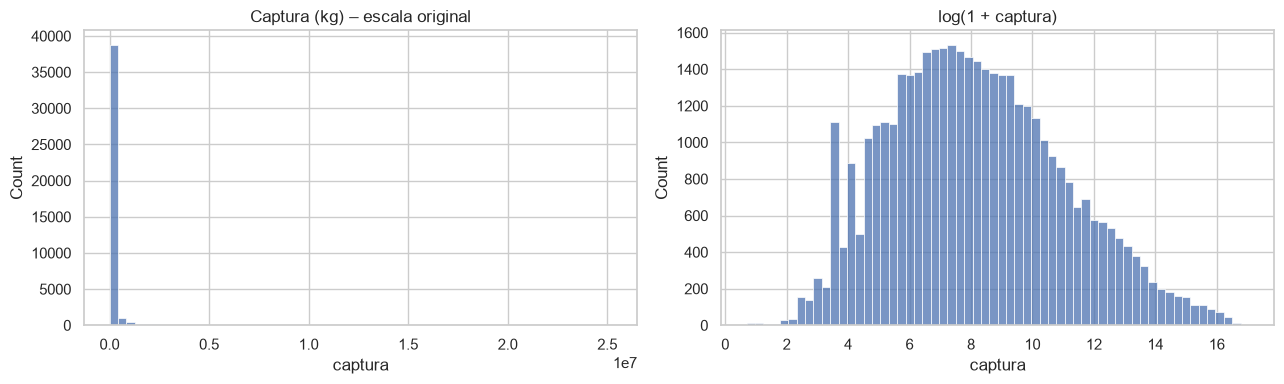

In [8]:
# Descripción de la captura e histogramas en escala original y logarítmica
cap = df_raw["captura"]
print(cap.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
print(f"\nCapturas = 0: {(cap == 0).sum()} | Capturas < 0: {(cap < 0).sum()}")
print(f"Asimetría: {cap.skew():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(cap, bins=60, ax=ax[0]); ax[0].set_title("Captura (kg) – escala original")
sns.histplot(np.log1p(cap.clip(lower=0)), bins=60, ax=ax[1]); ax[1].set_title("log(1 + captura)")
plt.tight_layout(); plt.show()

La captura es muy asimétrica (asimetría ≈ 10,8): la mediana es de 2,8 t por registro, pero el 1 % superior supera las 4.000 t. En escala logarítmica la distribución es aproximadamente simétrica. Acción: trabajar con `log1p(captura)`.

**Transformación `log1p`.** Calcula $\ln(1 + x)$. Se usa en lugar de $\ln(x)$ porque el logaritmo de 0 no está definido, y en las series mensuales hay meses con captura 0; con `log1p`, una captura 0 queda en 0. La transformación comprime los valores grandes: pasar de 100 kg a 200 kg y de 10.000 kg a 20.000 kg queda a la misma distancia. Así se pueden comparar series de tamaños muy distintos con un mismo criterio, y los pocos registros enormes no dominan el análisis. Es reversible: `expm1` devuelve la captura original.

### 3.4 Variables categóricas

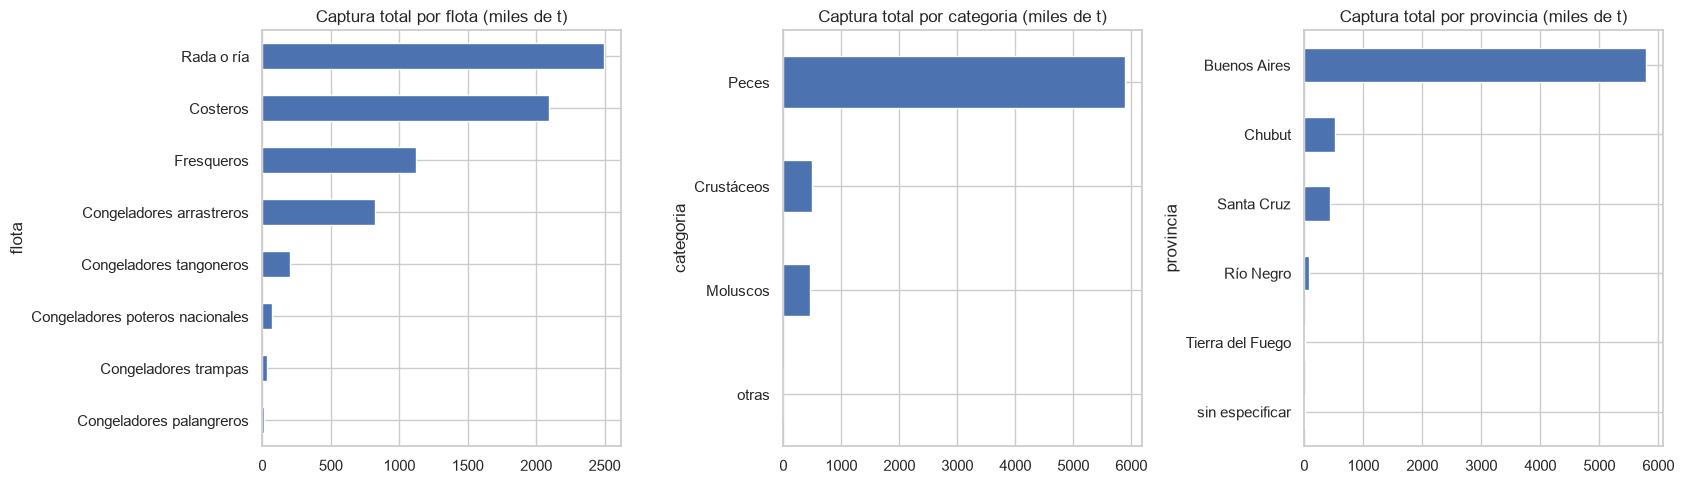

In [9]:
# Captura total por flota, categoría y provincia
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, col in zip(ax, ["flota", "categoria", "provincia"]):
    t = df_raw.groupby(col).captura.sum().sort_values() / 1e6
    t.plot.barh(ax=a); a.set_title(f"Captura total por {col} (miles de t)"); a.set_xlabel("")
plt.tight_layout(); plt.show()

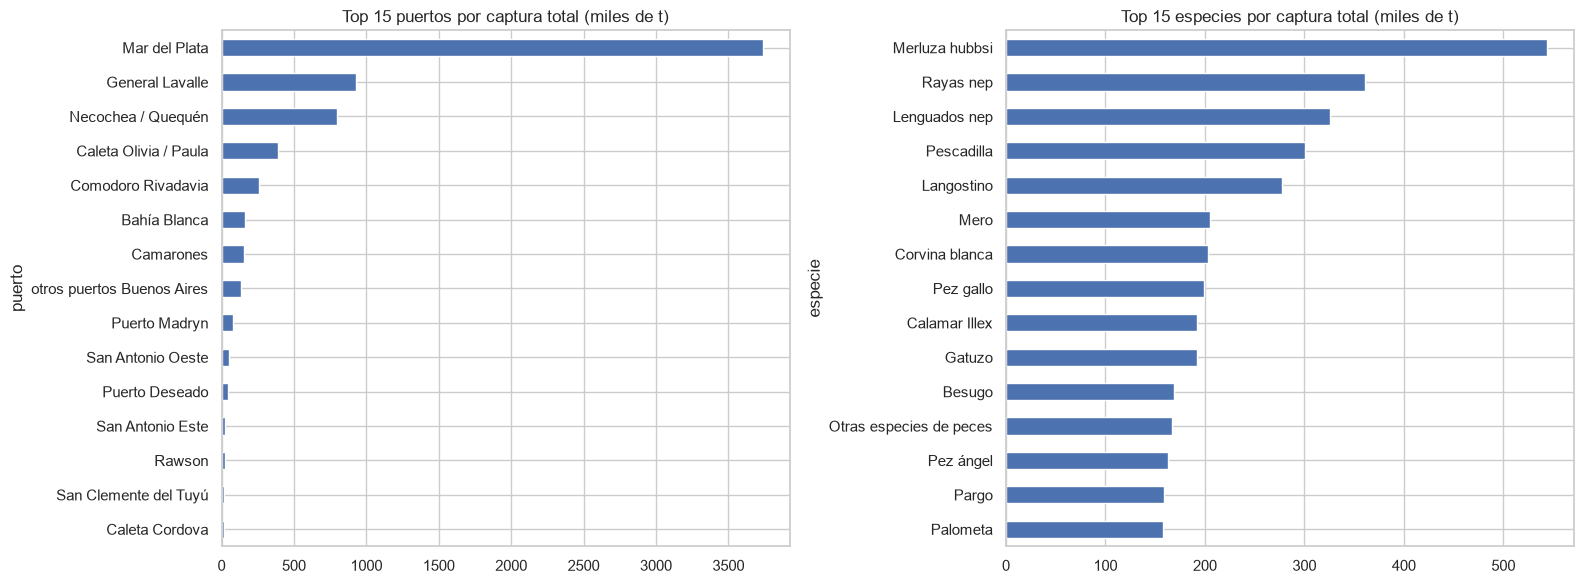

Las 5 especies principales concentran el 26.4% de la captura total.
Mar del Plata: 54.5% de la captura | 3 primeros puertos: 79.7%


In [10]:
# Los 15 puertos y las 15 especies con mayor captura total
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
(df_raw.groupby("puerto").captura.sum().nlargest(15).sort_values() / 1e6).plot.barh(ax=ax[0])
ax[0].set_title("Top 15 puertos por captura total (miles de t)")
(df_raw.groupby("especie").captura.sum().nlargest(15).sort_values() / 1e6).plot.barh(ax=ax[1])
ax[1].set_title("Top 15 especies por captura total (miles de t)")
plt.tight_layout(); plt.show()

cuota = df_raw.groupby("especie").captura.sum().sort_values(ascending=False)
print(f"Las 5 especies principales concentran el {cuota.head(5).sum() / cuota.sum():.1%} de la captura total.")
top_pto = df_raw.groupby("puerto").captura.sum().sort_values(ascending=False)
print(f"Mar del Plata: {top_pto.iloc[0] / top_pto.sum():.1%} de la captura | 3 primeros puertos: {top_pto.head(3).sum() / top_pto.sum():.1%}")

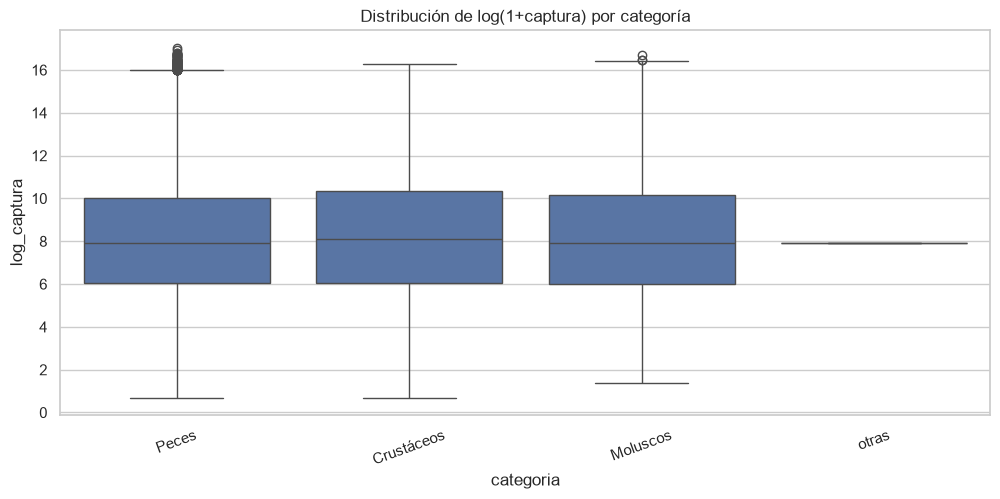

In [11]:
# Distribución de log(1+captura) por categoría
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_raw.assign(log_captura=np.log1p(df_raw.captura.clip(lower=0))),
            x="categoria", y="log_captura")
plt.title("Distribución de log(1+captura) por categoría"); plt.xticks(rotation=20); plt.show()

In [12]:
# Porcentaje de registros, porcentaje de captura y captura media por registro de cada flota, categoría y provincia
for col in ["flota", "categoria", "provincia"]:
    t = df_raw.groupby(col).captura.agg(registros="size", captura="sum")
    t["% registros"] = t.registros / t.registros.sum() * 100
    t["% captura"] = t.captura / t.captura.sum() * 100
    t["captura media por registro (t)"] = t.captura / t.registros / 1e3
    display(t.drop(columns="captura").sort_values("% captura", ascending=False).round(1))

,registros,% registros,% captura,captura media por registro (t)
flota,,,,
Rada o ría,12329,29.80,36.40,202.50
Costeros,12047,29.10,30.50,173.70
Fresqueros,9603,23.20,16.40,116.90
Congeladores arrastreros,5872,14.20,12.00,139.90
Congeladores tangoneros,840,2.00,2.90,239.40
Congeladores poteros nacionales,272,0.70,1.00,249.30
Congeladores trampas,183,0.40,0.50,185.40
Congeladores palangreros,194,0.50,0.20,74.00


,registros,% registros,% captura,captura media por registro (t)
categoria,,,,
Peces,36502,88.30,86.00,161.40
Crustáceos,2399,5.80,7.30,207.60
Moluscos,2438,5.90,6.70,188.80
otras,1,0.00,0.00,2.70


,registros,% registros,% captura,captura media por registro (t)
provincia,,,,
Buenos Aires,28395,68.70,84.50,203.90
Chubut,4733,11.40,7.70,110.90
Santa Cruz,1937,4.70,6.40,226.40
Río Negro,5013,12.10,1.10,15.50
Tierra del Fuego,1174,2.80,0.20,12.70
sin especificar,88,0.20,0.10,47.20


**Análisis de los resultados:**
- **Flota.** «Rada o ría» (36,4 %) y «Costeros» (30,5 %) reúnen dos tercios de la captura y el 59 % de los registros. Las flotas congeladoras especializadas (tangoneros, poteros, trampas y palangreros) tienen pocos registros (3,6 %), pero algunas tienen la mayor captura por registro (unas 240–250 t en tangoneros y poteros).
- **Categoría.** Los peces son el 88 % de los registros y el 86 % de la captura. En el boxplot, la mediana de `log1p(captura)` es casi igual en las tres categorías (entre 7,9 y 8,1, unas 3 t): la diferencia en los totales viene de la cantidad de registros, no del tamaño de cada desembarque. La categoría «otras» tiene un solo registro (algas) y se elimina con las especies «Otras…» (3.5).
- **Provincia y puerto.** Buenos Aires reúne el 84,5 % de la captura; solo Mar del Plata, el 54,5 %, y los tres primeros puertos, el 79,7 %. Río Negro tiene el 12,1 % de los registros pero el 1,1 % de la captura (unas 15 t por registro), lo que indica pesca en pequeña escala.
- **Especie.** La captura está más repartida entre especies: las 5 principales (encabezadas por la merluza hubbsi) suman el 26,4 %.

**Acción:** como pocos puertos y flotas concentran casi toda la captura, un umbral único en kilos quedaría dominado por Mar del Plata. Por eso la anomalía se define dentro de cada serie especie–puerto y en escala logarítmica (4.1). Si estas variables se relacionan con la probabilidad de anomalía se evalúa en 4.4.

### 3.5 Categorías «otros»

En los datos hay tres tipos de categorías «otros»:

1. Los puertos «otros puertos» y «otros puertos Buenos Aires», que suman varios puertos menores.
2. Las especies residuales «Otras especies de peces / crustáceos / moluscos» y «Otras - Algas», que agrupan especies que no se informan por separado. Son distintas de las especies «nep» (no especificadas en otra partida, por ejemplo «Rayas nep»), que corresponden a un solo grupo de especies.
3. El valor «otras especies» de `especie_agrupada`, que es una agrupación de gestión; cada registro mantiene su `especie` real (por ejemplo «Pez gallo»).

In [13]:
# Cantidad de registros y porcentaje de la captura de cada tipo de categoría «otros»
es_otro_pto = df_raw.puerto.str.contains("otros puertos", case=False)
es_otra_esp = df_raw.especie.str.lower().str.startswith("otras")
es_otra_agr = df_raw.especie_agrupada.str.lower() == "otras especies"
tot = df_raw.captura.sum()
resumen = pd.DataFrame({
    "registros": [m.sum() for m in (es_otro_pto, es_otra_esp, es_otra_agr)],
    "% registros": [m.mean() * 100 for m in (es_otro_pto, es_otra_esp, es_otra_agr)],
    "% captura": [df_raw[m].captura.sum() / tot * 100 for m in (es_otro_pto, es_otra_esp, es_otra_agr)],
}, index=["puertos «otros»", "especies residuales «Otras…»", "especie_agrupada «otras especies»"])
display(resumen.round(1))
display(df_raw[es_otra_esp].groupby("especie").captura.agg(registros="size", captura_t=lambda s: s.sum() / 1e3).round(0))
print("Especies distintas dentro de «otras especies»:", df_raw[es_otra_agr].especie.nunique())

,registros,% registros,% captura
puertos «otros»,2380,5.80,2.00
especies residuales «Otras…»,1196,2.90,2.50
especie_agrupada «otras especies»,16787,40.60,37.00


,registros,captura_t
especie,,
"Otras - Algas, etc.",1,3.00
Otras especies de crustác,6,"3,192.00"
Otras especies de molusco,28,"1,686.00"
Otras especies de peces,1161,"167,016.00"


Especies distintas dentro de «otras especies»: 67


**Decisión sobre las categorías «otros»:**
1. **Puertos «otros» (5,8 % de los registros, 2,0 % de la captura): se excluyen.** No son un puerto real sino una suma de puertos menores, que puede cambiar si un puerto empieza a informarse por separado o deja de operar. Esos cambios aparecerían como anomalías sin serlo. Además, son los únicos registros sin coordenadas.
2. **Especies «Otras…» (2,9 % de los registros, 2,5 % de la captura): se excluyen** por el mismo motivo: mezclan especies distintas cuya composición puede variar. Las especies «nep» se conservan, porque cada una es un grupo de especies que se registra siempre de la misma forma; además, «Rayas nep» y «Lenguados nep» están entre las de mayor captura.
3. **`especie_agrupada` «otras especies» (40,6 % de los registros): se conserva.** Las series se definen con `especie`, así que estos registros corresponden a especies reales (por ejemplo «Pez gallo»). `especie_agrupada` solo se usa como predictora, y su relación con la variable objetivo se evalúa en 4.4.

En total se excluyen 3.458 registros (8,4 %) en el paso 4 del preprocesamiento.

### 3.6 Dimensión temporal y estacionalidad

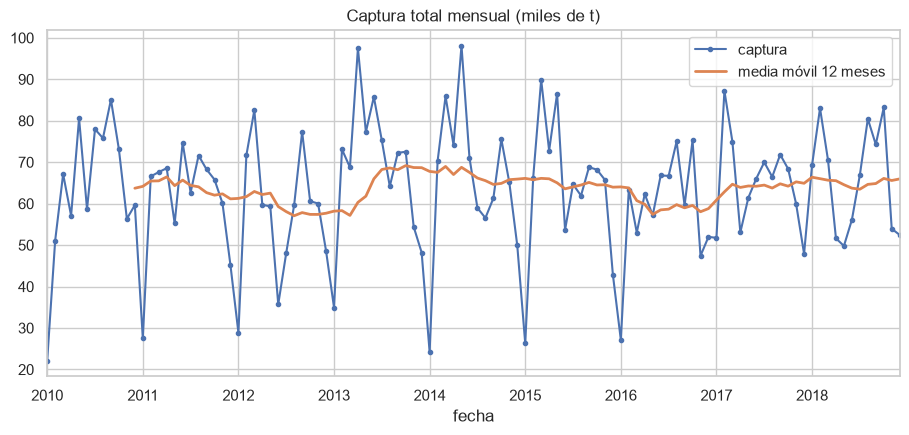

In [14]:
# Captura total mensual y media móvil de 12 meses
df_eda = df_raw.copy()
df_eda["fecha"] = pd.to_datetime(df_eda["fecha"].astype(str).str[:7], format="%Y-%m")
df_eda["anio"], df_eda["mes"] = df_eda.fecha.dt.year, df_eda.fecha.dt.month

mensual = df_eda.groupby("fecha").captura.sum() / 1e6
ax = mensual.plot(marker=".", title="Captura total mensual (miles de t)")
mensual.rolling(12).mean().plot(ax=ax, lw=2, label="media móvil 12 meses"); ax.legend(); plt.show()

**Hallazgo:** la captura total tiene un patrón que se repite cada año. Entre 2010 y 2016 el mes de menor captura fue siempre enero (entre 22 y 35 mil t, contra un promedio de 66 mil t en el resto de los meses); en 2017 y 2018 esa baja fue menor. La media móvil de 12 meses se mantiene entre 57 y 69 mil t, por lo que no hay una tendencia sostenida.

**Acción:** la baja de enero es estacional y no debe considerarse una anomalía, por eso el valor esperado de cada mes se calcula con el mismo mes de los años anteriores (4.1). Como no hay tendencia, no hace falta quitarla; el año se evalúa como predictora en 4.4.

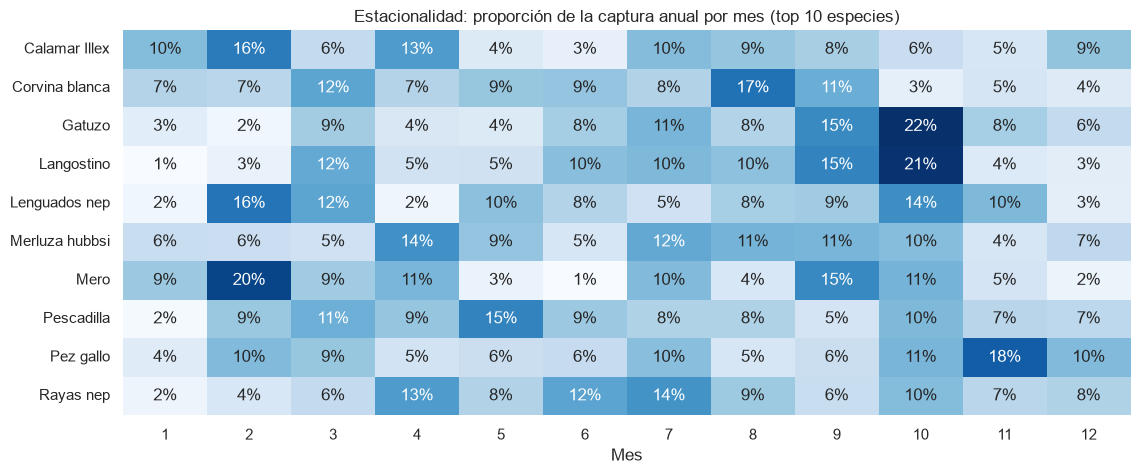

In [15]:
# Proporción de la captura anual que corresponde a cada mes en las 10 especies principales
top_esp = df_eda.groupby("especie").captura.sum().nlargest(10).index
piv = (df_eda[df_eda.especie.isin(top_esp)]
       .groupby(["especie", "anio", "mes"]).captura.sum()
       .groupby(["especie", "mes"]).mean().unstack())
piv_norm = piv.div(piv.sum(axis=1), axis=0)
plt.figure(figsize=(13, 5))
sns.heatmap(piv_norm, cmap="Blues", annot=True, fmt=".0%", cbar=False)
plt.title("Estacionalidad: proporción de la captura anual por mes (top 10 especies)")
plt.xlabel("Mes"); plt.ylabel(""); plt.show()

Cada especie tiene un patrón estacional propio (zafras). Acción: definir la anomalía respecto del mismo mes en años anteriores y dentro de la misma serie especie–puerto, no con un umbral global.

### 3.7 Continuidad de las series especie–puerto

Series especie–puerto: 719
       n_meses  cobertura
count   719.00     719.00
mean     29.21       0.54
std      35.44       0.37
min       1.00       0.02
25%       2.00       0.18
50%      10.00       0.50
75%      50.00       1.00
max     108.00       1.00


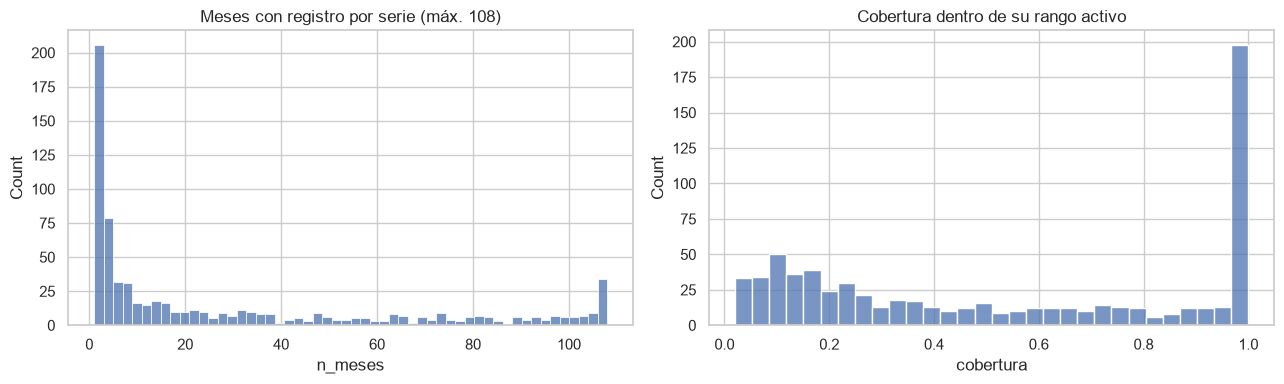

In [16]:
# Cantidad de meses con registro y cobertura de cada serie especie–puerto
serie = df_eda.groupby(["especie", "puerto"]).fecha.agg(n_meses="nunique", inicio="min", fin="max")
serie["meses_rango"] = ((serie.fin.dt.year - serie.inicio.dt.year) * 12 + serie.fin.dt.month - serie.inicio.dt.month + 1)
serie["cobertura"] = serie.n_meses / serie.meses_rango
print(f"Series especie–puerto: {len(serie):,}")
print(serie[["n_meses", "cobertura"]].describe())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(serie.n_meses, bins=54, ax=ax[0]); ax[0].set_title("Meses con registro por serie (máx. 108)")
sns.histplot(serie.cobertura, bins=30, ax=ax[1]); ax[1].set_title("Cobertura dentro de su rango activo")
plt.tight_layout(); plt.show()

La mitad de las series tiene 10 meses o menos con registros (especies ocasionales o puertos con poca actividad). Con tan poca historia no se puede estimar qué es lo habitual. Acción: filtrar las series con menos de 36 meses con captura (paso 9).

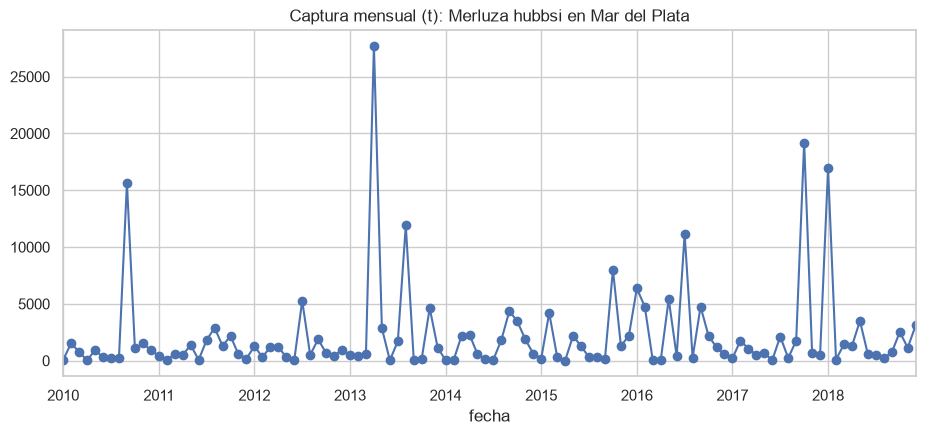

In [17]:
# Captura mensual de la serie con mayor captura total
ej = df_eda.groupby(["especie", "puerto"]).captura.sum().idxmax()
s = df_eda[(df_eda.especie == ej[0]) & (df_eda.puerto == ej[1])].groupby("fecha").captura.sum() / 1e3
s.plot(marker="o", title=f"Captura mensual (t): {ej[0]} en {ej[1]}"); plt.show()

**Hallazgo:** incluso en la serie más importante (merluza hubbsi en Mar del Plata), la captura mensual suele estar por debajo de 5.000 t, con picos aislados de 12.000 a 28.000 t (2010, 2013, 2016–2018) que no se repiten en el mismo mes de otros años.

**Acción:** estos picos son el tipo de evento que el modelo debe detectar (`aumento`). Para que no alteren la referencia de los meses siguientes, el valor esperado y la dispersión se calculan con mediana y MAD en lugar de media y desvío estándar (4.1).

In [18]:
# Proporción de meses de cada serie según la cantidad de flotas que desembarcan
flotas_por_serie = df_eda.groupby(["especie", "puerto", "fecha"]).flota.nunique()
print(flotas_por_serie.value_counts(normalize=True).sort_index().rename("proporción"))

flota
1   0.56
2   0.25
3   0.15
4   0.03
5   0.00
Name: proporción, dtype: float64


**Hallazgo:** en el 56 % de los meses de una serie desembarca una sola flota, en el 25 % dos y en el 18 % tres o más.

**Acción:** como la unidad de análisis es la serie especie–puerto, se suman las flotas (paso 7) y se conservan como predictoras la flota principal del mes (la de mayor captura) y la cantidad de flotas.

### 3.8 Conclusiones del EDA

| Hallazgo | Acción | Sección |
|---|---|---|
| La captura es muy asimétrica | Usar `log1p(captura)` | 3.3, paso 10 |
| Mar del Plata concentra el 54,5 % de la captura | Definir la anomalía dentro de cada serie especie–puerto | 3.4, 4.1 |
| «Otros puertos» y las especies «Otras…» no son una unidad real | Excluirlas | 3.5, paso 4 |
| Las únicas coordenadas faltantes son las de «otros puertos» | No imputar: se eliminan con el paso anterior | 3.2, paso 4 |
| 15 % de registros repiten fecha–flota–puerto–especie | Sumarlos al agregar | 3.2, paso 7 |
| `provincia_id`, `departamento` y `departamento_id` son redundantes | Eliminarlas | 3.1, paso 5 |
| Cada especie tiene su estacionalidad y enero es el mes de menor captura | Comparar cada mes con el mismo mes de años anteriores | 3.6, 4.1 |
| No hay una tendencia sostenida | No quitar tendencia; evaluar `anio` como predictora | 3.6, 4.4 |
| Hay picos aislados muy grandes | Usar mediana y MAD | 3.7, 4.1 |
| Los meses sin desembarque no aparecen como fila | Completarlos con captura 0 | 3.1, paso 8 |
| La mitad de las series tiene 10 meses o menos | Filtrar series con menos de 36 meses con captura | 3.7, paso 9 |
| En el 44 % de los meses opera más de una flota | Sumar flotas y conservar flota principal y cantidad de flotas | 3.7, paso 7 |
| El dataset no tiene variable objetivo | Construirla a partir del histórico de cada serie | 4.1 |

La variable objetivo se calcula sobre la serie mensual especie–puerto, que se obtiene recién al agregar los registros (sección 4). Por eso el EDA de la variable objetivo y el análisis de dependencia con las predictoras se presentan en las secciones 4.2 y 4.4.

## 4. Limpieza y preprocesamiento (con justificación)

| Paso | Decisión | Justificación |
|---|---|---|
| 1 | Normalizar textos (espacios, mayúsculas) | Evita que un mismo puerto o especie aparezca como categorías distintas. |
| 2 | Eliminar duplicados exactos | Son copias del mismo registro y aumentarían la captura. |
| 3 | Convertir `fecha` a fecha y obtener `anio` y `mes` | El mes refleja la estacionalidad y el año, la tendencia. |
| 4 | Excluir «otros puertos», «otros puertos Buenos Aires» y las especies «Otras…» | Mezclan puertos o especies cuya composición puede cambiar; una variación en esas series no indica una anomalía real (3.5). |
| 5 | Eliminar `provincia_id`, `departamento`, `departamento_id` | Repiten la información de `provincia` y `puerto`. |
| 6 | Controlar que no haya capturas negativas o faltantes | No tienen sentido físico. En estos datos no hay; los ceros se mantienen porque el paso 8 los agrega a propósito. |
| 7 | Agregar por mes–especie–puerto (sumando flotas) | La unidad de análisis es la serie especie–puerto. Se guardan la flota principal y la cantidad de flotas. |
| 8 | Completar los meses sin registro con captura 0 dentro del período activo de cada serie | Un mes sin desembarque en una serie activa es una captura nula, no un dato faltante. |
| 9 | Filtrar series con menos de 36 meses con captura | Sin historia suficiente no se puede definir lo normal para esa serie. |
| 10 | Transformar `captura` con `log1p` | Reduce la asimetría (3.3). |
| 11 | Construir la variable objetivo `anomalia` y las predictoras con información hasta *t−1* | Evita usar información del mes que se quiere predecir (*data leakage*). |

In [19]:
# Pasos 1 a 3: normalización de textos, eliminación de duplicados exactos y conversión de fechas
df = df_raw.copy()
n0 = len(df)
cat_cols = ["flota", "puerto", "provincia", "categoria", "especie", "especie_agrupada"]
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip().str.replace(r"\s+", " ", regex=True).str.title()

df = df.drop_duplicates()
n_dup = n0 - len(df)

df["fecha"] = pd.to_datetime(df["fecha"].astype(str).str[:7], format="%Y-%m")
df["anio"], df["mes"] = df.fecha.dt.year, df.fecha.dt.month
print(f"Registros iniciales: {n0:,} | duplicados eliminados: {n_dup:,}")

Registros iniciales: 41,340 | duplicados eliminados: 0


In [20]:
# Pasos 4 a 6: exclusión de las categorías «otros», eliminación de columnas redundantes y control de capturas inválidas
otros = df.puerto.str.startswith("Otros Puertos") | df.especie.str.startswith("Otras")
n_otros = int(otros.sum())
df = df[~otros]

df = df.drop(columns=[c for c in ["provincia_id", "departamento", "departamento_id"] if c in df])

df["captura"] = pd.to_numeric(df["captura"], errors="coerce")
n_inv = int((df.captura.isna() | (df.captura < 0)).sum())
df = df[df.captura.notna() & (df.captura >= 0)]

print(f"«Otros» excluidos: {n_otros:,} | capturas inválidas eliminadas: {n_inv:,} | registros finales: {len(df):,}")
print("Faltantes en coordenadas:", df[["latitud", "longitud"]].isna().sum().to_dict())

«Otros» excluidos: 3,458 | capturas inválidas eliminadas: 0 | registros finales: 37,882
Faltantes en coordenadas: {'latitud': 0, 'longitud': 0}


In [21]:
# Paso 7: agregación por especie, puerto y mes, con flota principal, cantidad de flotas y atributos de especie y puerto
por_flota = df.groupby(["especie", "puerto", "fecha", "flota"], as_index=False).captura.sum()
flota_dom = (por_flota.sort_values("captura", ascending=False)
             .drop_duplicates(["especie", "puerto", "fecha"])
             [["especie", "puerto", "fecha", "flota"]].rename(columns={"flota": "flota_principal"}))
agg = (df.groupby(["especie", "puerto", "fecha"], as_index=False)
         .agg(captura=("captura", "sum"), n_flotas=("flota", "nunique")))
agg = agg.merge(flota_dom, on=["especie", "puerto", "fecha"])

attr_esp = df.groupby("especie")[["categoria", "especie_agrupada"]].agg(lambda s: s.mode().iloc[0])
attr_pto = df.groupby("puerto")[["provincia", "latitud", "longitud"]].agg(lambda s: s.mode().iloc[0])
print("Filas tras agregar:", f"{len(agg):,}")

Filas tras agregar: 18,839


In [22]:
# Paso 8: completar con captura 0 los meses sin registro dentro del período activo de cada serie
def completar(g):
    rango = pd.date_range(g.fecha.min(), g.fecha.max(), freq="MS")
    return g.set_index("fecha").reindex(rango).rename_axis("fecha").reset_index()

agg = (agg.groupby(["especie", "puerto"], group_keys=True)[["fecha", "captura", "n_flotas", "flota_principal"]]
          .apply(completar).reset_index(level=[0, 1]).reset_index(drop=True))
agg["captura"] = agg.captura.fillna(0)
agg["n_flotas"] = agg.n_flotas.fillna(0).astype(int)
agg["flota_principal"] = agg.groupby(["especie", "puerto"]).flota_principal.transform(
    lambda s: s.fillna(s.mode().iloc[0]))
print("Filas con meses completados:", f"{len(agg):,}")

Filas con meses completados: 38,019


In [23]:
# Pasos 9 y 10: filtro de series con al menos 36 meses con captura y transformación logarítmica
MIN_MESES = 36
meses_activos = agg[agg.captura > 0].groupby(["especie", "puerto"]).size()
validas = meses_activos[meses_activos >= MIN_MESES].index
n_series_tot = agg.groupby(["especie", "puerto"]).ngroups
agg = agg.set_index(["especie", "puerto"]).loc[validas].reset_index()

agg["log_captura"] = np.log1p(agg.captura)
agg["anio"], agg["mes"] = agg.fecha.dt.year, agg.fecha.dt.month
agg = agg.join(attr_esp, on="especie").join(attr_pto, on="puerto")
agg = agg.sort_values(["especie", "puerto", "fecha"]).reset_index(drop=True)
print(f"Series totales: {n_series_tot:,} | series con >= {MIN_MESES} meses con captura: {len(validas):,}")
print("Dimensiones tras el preprocesamiento:", agg.shape)

Series totales: 627 | series con >= 36 meses con captura: 198
Dimensiones tras el preprocesamiento: (20669, 14)


### 4.1 Construcción de la variable objetivo `anomalia`

La variable objetivo es categórica y toma tres valores: `normal`, `caida` y `aumento`. Para cada serie especie–puerto y cada mes *t* se calcula, usando solo meses anteriores:

1. **Valor esperado** $\hat{y}_t$: mediana de `log_captura` del mismo mes en los años anteriores (mínimo 2 años). Así se tiene en cuenta la estacionalidad.
2. **Dispersión habitual** $s_t$: MAD de los residuos $y - \hat{y}$ en los 24 meses anteriores, multiplicado por 1,4826, con un mínimo de 0,25 para las series muy estables.
3. **Puntaje** $z_t = (y_t - \hat{y}_t)/s_t$.
4. **Clase**: `aumento` si $z_t > 3$, `caida` si $z_t < -3$ y `normal` en otro caso.

Los dos primeros años de cada serie quedan sin etiqueta porque se usan como historia.

**Mediana, MAD y puntaje *z* robusto.** El puntaje *z* habitual usa la media y el desvío estándar, pero estos se alteran con los mismos valores extremos que queremos detectar. Por eso usamos la mediana y el MAD (la mediana de las distancias a la mediana), que casi no cambian con unos pocos valores extremos. El factor 1,4826 hace que el MAD sea comparable con el desvío estándar, de modo que $|z| > 3$ significa "a más de 3 desvíos de lo habitual".

Ejemplo: en los valores 10, 11, 12, 11 y 50, la media es 18,8 y el desvío 17,4, así que el 50 queda a 1,8 desvíos y parecería normal. La mediana es 11 y el MAD es 1, así que el 50 queda a $(50 - 11)/1{,}4826 \approx 26$ desvíos robustos y se detecta como anomalía.

In [24]:
# Cálculo del valor esperado, la dispersión, el puntaje z y la variable objetivo de tres clases
K, PISO, MIN_ANIOS = 3.0, 0.25, 2
CLASES = ["normal", "caida", "aumento"]

g = agg.groupby(["especie", "puerto", "mes"]).log_captura
agg["esperado"] = g.transform(lambda s: s.shift(1).expanding(min_periods=MIN_ANIOS).median())
agg["residuo"] = agg.log_captura - agg.esperado

gs = agg.groupby(["especie", "puerto"]).residuo
agg["escala"] = gs.transform(
    lambda s: s.shift(1).rolling(24, min_periods=12).apply(lambda x: np.median(np.abs(x - np.median(x))), raw=True)
) * 1.4826
agg["escala"] = agg.escala.clip(lower=PISO)
agg["z"] = agg.residuo / agg.escala

agg["anomalia"] = pd.Series(np.select([agg.z > K, agg.z < -K], ["aumento", "caida"], "normal"), index=agg.index)
agg.loc[agg.z.isna(), "anomalia"] = np.nan
agg["anomalia"] = pd.Categorical(agg.anomalia, categories=CLASES)

et = agg.dropna(subset=["anomalia"])
print(f"Meses etiquetados: {len(et):,}")

Meses etiquetados: 11,165


### 4.2 EDA de la variable objetivo

,n,proporción
anomalia,,
normal,10546,0.94
caida,373,0.03
aumento,246,0.02


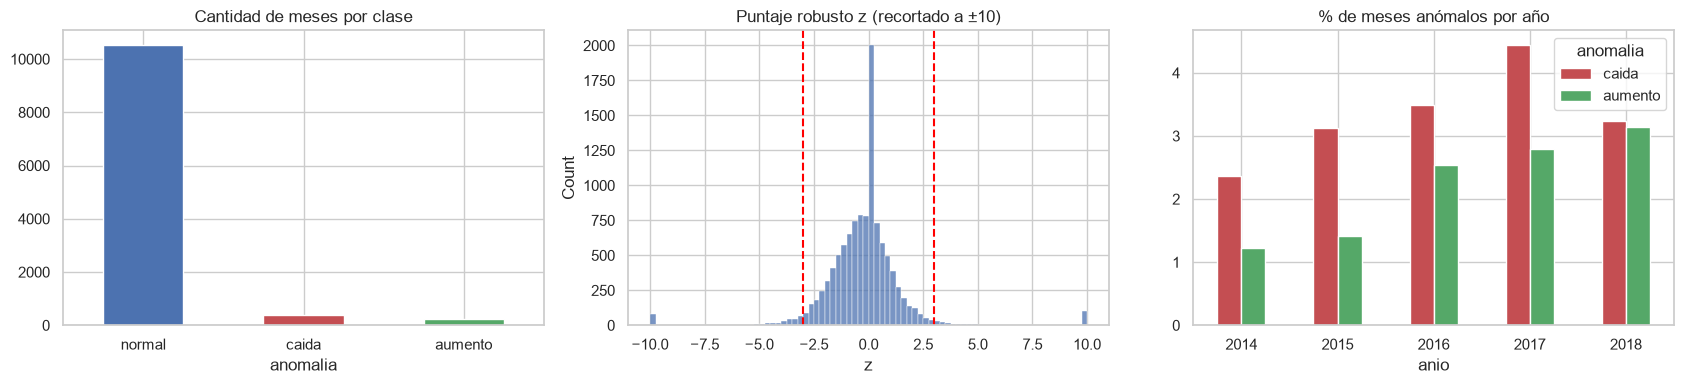

In [25]:
# Cantidad de meses por clase, distribución del puntaje z y porcentaje de anomalías por año
dist = et.anomalia.value_counts().reindex(CLASES).to_frame("n")
dist["proporción"] = (dist.n / dist.n.sum()).round(3)
display(dist)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
dist.n.plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52", "#55A868"], rot=0, title="Cantidad de meses por clase")
sns.histplot(et.z.clip(-10, 10), bins=80, ax=ax[1])
for v in (-K, K): ax[1].axvline(v, color="red", ls="--")
ax[1].set_title("Puntaje robusto z (recortado a ±10)")
(pd.crosstab(et.anio, et.anomalia, normalize="index")[["caida", "aumento"]] * 100).plot.bar(
    ax=ax[2], color=["#C44E52", "#55A868"], rot=0, title="% de meses anómalos por año")
plt.tight_layout(); plt.show()

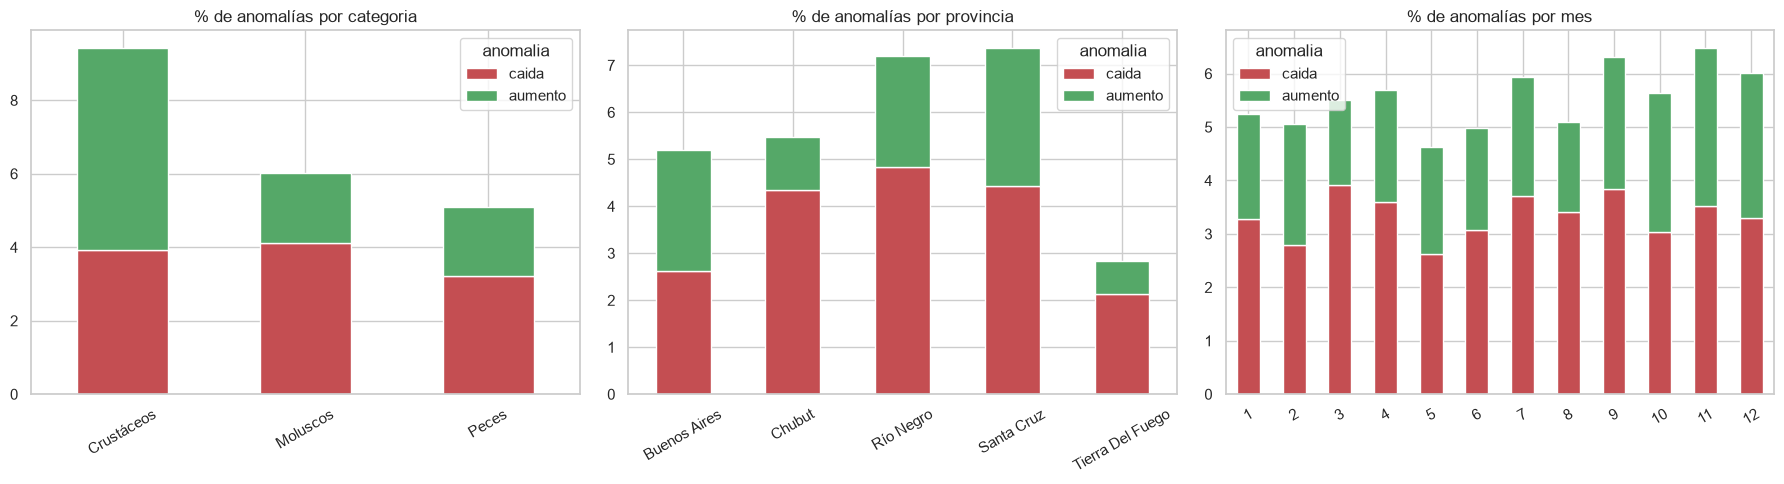

In [26]:
# Porcentaje de caídas y aumentos por categoría, provincia y mes
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, col in zip(ax, ["categoria", "provincia", "mes"]):
    (pd.crosstab(et[col], et.anomalia, normalize="index")[["caida", "aumento"]] * 100).plot.bar(
        ax=a, stacked=True, color=["#C44E52", "#55A868"], title=f"% de anomalías por {col}")
    a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

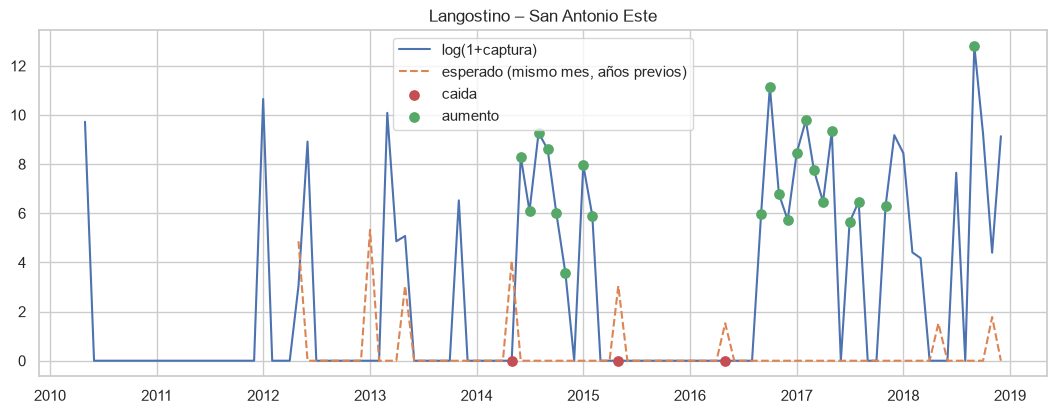

In [27]:
# Serie con más anomalías, con su valor esperado y los meses marcados como caída o aumento
ej_s = et[et.anomalia != "normal"].groupby(["especie", "puerto"]).size().idxmax()
s = agg[(agg.especie == ej_s[0]) & (agg.puerto == ej_s[1])]
plt.figure(figsize=(13, 4.5))
plt.plot(s.fecha, s.log_captura, label="log(1+captura)")
plt.plot(s.fecha, s.esperado, ls="--", label="esperado (mismo mes, años previos)")
for clase, color in (("caida", "#C44E52"), ("aumento", "#55A868")):
    a = s[s.anomalia == clase]
    plt.scatter(a.fecha, a.log_captura, color=color, zorder=3, s=45, label=clase)
plt.title(f"{ej_s[0]} – {ej_s[1]}"); plt.legend(); plt.show()

**Análisis de los resultados:**
- **Clases.** De los 11.165 meses etiquetados, el 94,5 % es `normal`, el 3,3 % `caida` (373 meses) y el 2,2 % `aumento` (246 meses). Las clases están muy desbalanceadas, lo que se tiene en cuenta en la sección 7.
- **Puntaje z.** Está centrado en 0 y es aproximadamente simétrico. El pico en 0 corresponde a meses sin captura en series que ese mes tampoco suelen tener captura.
- **Por año.** Las anomalías pasan del 3,6 % en 2014 al 7,2 % en 2017 (6,4 % en 2018), y los aumentos crecen más que las caídas. Como la proporción cambia con los años, la validación tiene que ser temporal: el modelo se entrena con años que tienen menos anomalías que los de validación y prueba.
- **Por categoría y provincia.** Los crustáceos tienen casi el doble de anomalías que los peces (9,4 % frente a 5,1 %), sobre todo aumentos. Río Negro y Santa Cruz tienen alrededor del 7 %, con más caídas; Buenos Aires, 5,2 %; Tierra del Fuego, 2,8 %.
- **Por mes.** La proporción varía poco (entre 4,6 % y 6,5 %) y sin un patrón claro. Es lo esperable, porque cada mes se compara con el mismo mes de años anteriores.
- **Ejemplo (Langostino – San Antonio Este).** En esta serie casi todos los meses tienen captura esperada 0. Cuando la pesca se activa (2014 y 2016–2017), muchos meses seguidos quedan como `aumento`, porque el valor esperado tarda en adaptarse. Esto explica que las anomalías previas sean de las predictoras más relacionadas con la clase (4.4).

**Acción:** ponderar las clases y usar métricas por clase en el modelo (sección 7), y revisar en la próxima entrega cómo cambia la etiqueta con otros valores de los parámetros (próximos pasos).

### 4.3 Variables predictoras (solo información hasta *t−1*)

Como el objetivo es anticipar la anomalía, ninguna predictora usa el valor del mes *t*:

- Rezagos de `log_captura`: *t−1, t−2, t−3, t−12*.
- Medias y desvíos móviles de 3, 6 y 12 meses (desde *t−1* hacia atrás).
- Valor esperado del mes *t* (`esperado`) y su diferencia con el último valor observado.
- Clase del mes anterior (`anomalia_lag1`) y cantidad de caídas y de aumentos en los 12 meses previos.
- Proporción de meses sin desembarque en los últimos 12 meses.
- Calendario: mes (codificado con seno y coseno) y año.
- Contexto: categoría, especie agrupada, provincia, puerto, flota principal y cantidad de flotas en *t−1*.

**Codificación del mes con seno y coseno.** Si el mes se usa como un número del 1 al 12, el modelo interpreta que diciembre (12) está lejos de enero (1), aunque son meses consecutivos. Para evitarlo, cada mes se ubica sobre un círculo con dos variables: $\sin(2\pi \cdot \text{mes}/12)$ y $\cos(2\pi \cdot \text{mes}/12)$. Así la distancia entre diciembre y enero es igual a la de cualquier otro par de meses consecutivos.

In [28]:
# Cálculo de las variables predictoras de cada mes con información hasta t-1
gb = agg.groupby(["especie", "puerto"])
y_prev = gb.log_captura.shift(1)
agg["lag_1"] = y_prev
agg["lag_2"] = gb.log_captura.shift(2)
agg["lag_3"] = gb.log_captura.shift(3)
agg["lag_12"] = gb.log_captura.shift(12)
for w in (3, 6, 12):
    agg[f"media_{w}"] = y_prev.groupby([agg.especie, agg.puerto]).transform(lambda s: s.rolling(w, min_periods=2).mean())
    agg[f"std_{w}"] = y_prev.groupby([agg.especie, agg.puerto]).transform(lambda s: s.rolling(w, min_periods=2).std())
agg["dif_esperado_lag1"] = agg.esperado - agg.lag_1
agg["dif_lag1_lag12"] = agg.lag_1 - agg.lag_12
agg["anomalia_lag1"] = gb.anomalia.shift(1)
for clase, nombre in (("caida", "caidas_12m"), ("aumento", "aumentos_12m")):
    ind = (agg.anomalia == clase).astype(float).where(agg.anomalia.notna())
    agg[nombre] = ind.groupby([agg.especie, agg.puerto]).transform(lambda s: s.shift(1).rolling(12, min_periods=1).sum())
agg["prop_sin_desembarque_12m"] = (agg.captura == 0).astype(float).groupby([agg.especie, agg.puerto]).transform(
    lambda s: s.shift(1).rolling(12, min_periods=1).mean())
agg["n_flotas_lag1"] = gb.n_flotas.shift(1)
agg["mes_sin"] = np.sin(2 * np.pi * agg.mes / 12)
agg["mes_cos"] = np.cos(2 * np.pi * agg.mes / 12)

In [29]:
# Dataset final con claves, variable objetivo, variables auxiliares y predictoras
FEATURES_NUM = ["lag_1", "lag_2", "lag_3", "lag_12", "media_3", "std_3", "media_6", "std_6",
                "media_12", "std_12", "esperado", "dif_esperado_lag1", "dif_lag1_lag12",
                "caidas_12m", "aumentos_12m", "prop_sin_desembarque_12m", "n_flotas_lag1",
                "mes_sin", "mes_cos", "anio", "latitud", "longitud"]
FEATURES_CAT = ["categoria", "especie_agrupada", "provincia", "puerto", "flota_principal", "anomalia_lag1"]
TARGET = "anomalia"

df_limpio = agg.dropna(subset=[TARGET, "lag_1"]).copy()
df_limpio[TARGET] = df_limpio[TARGET].astype(str)
df_limpio["anomalia_lag1"] = df_limpio["anomalia_lag1"].astype(object)
cols_final = (["fecha", "especie", "puerto"] + FEATURES_CAT[:3] + ["flota_principal", "captura", "log_captura",
              "z", TARGET, "anomalia_lag1"] + [c for c in FEATURES_NUM if c not in ("latitud", "longitud")]
              + ["latitud", "longitud", "mes"])
df_limpio = df_limpio[list(dict.fromkeys(cols_final))].reset_index(drop=True)
df_limpio.head()

,fecha,especie,puerto,categoria,especie_agrupada,provincia,flota_principal,captura,log_captura,z,anomalia,anomalia_lag1,lag_1,lag_2,lag_3,lag_12,media_3,std_3,media_6,std_6,media_12,std_12,esperado,dif_esperado_lag1,dif_lag1_lag12,caidas_12m,aumentos_12m,prop_sin_desembarque_12m,n_flotas_lag1,mes_sin,mes_cos,anio,latitud,longitud,mes
0,2014-01-01,Abadejo,Mar Del Plata,Peces,Abadejo,Buenos Aires,Fresqueros,680.00,6.52,-1.44,normal,NaN,9.53,11.27,8.37,13.04,9.72,1.46,10.02,2.73,10.95,2.15,11.03,1.50,-3.51,NaN,NaN,0.00,3.00,0.50,0.87,2014,-38.05,-57.54,1
1,2014-02-01,Abadejo,Mar Del Plata,Peces,Abadejo,Buenos Aires,Rada O Ría,"116,925.00",11.67,-0.07,normal,normal,6.52,9.53,11.27,11.07,9.11,2.40,8.61,1.63,10.41,2.39,11.91,5.38,-4.54,0.00,0.00,0.00,2.00,0.87,0.50,2014,-38.05,-57.54,2
2,2014-03-01,Abadejo,Mar Del Plata,Peces,Abadejo,Buenos Aires,Congeladores Arrastreros,"13,778,127.00",16.44,1.25,normal,normal,11.67,6.52,9.53,12.20,9.24,2.58,9.27,1.96,10.46,2.41,12.15,0.48,-0.53,0.00,0.00,0.00,4.00,1.00,0.00,2014,-38.05,-57.54,3
3,2014-04-01,Abadejo,Mar Del Plata,Peces,Abadejo,Buenos Aires,Congeladores Arrastreros,"1,230.00",7.12,-1.03,normal,normal,16.44,11.67,6.52,12.18,11.54,4.96,10.63,3.42,10.81,2.94,10.64,-5.80,4.26,0.00,0.00,0.00,3.00,0.87,-0.50,2014,-38.05,-57.54,4
4,2014-05-01,Abadejo,Mar Del Plata,Peces,Abadejo,Buenos Aires,Fresqueros,"1,176.00",7.07,-1.11,normal,normal,7.12,16.44,11.67,10.85,11.74,4.66,10.42,3.62,10.39,3.09,10.90,3.79,-3.74,0.00,0.00,0.00,3.00,0.50,-0.87,2014,-38.05,-57.54,5


### 4.4 Análisis de dependencia entre las predictoras y la variable objetivo

Como la variable objetivo es categórica, la prueba depende del tipo de predictora:

| Tipo de predictora | Prueba | Hipótesis nula |
|---|---|---|
| Categórica | Chi-cuadrado de independencia | La predictora y la clase son independientes |
| Numérica | ANOVA de un factor | La media de la predictora es igual en las tres clases |

Si el *p*-valor es menor que 0,05 se rechaza la hipótesis nula y se considera que la predictora está relacionada con la variable objetivo.

Consideraciones:
- El chi-cuadrado requiere frecuencias esperadas de al menos 5 en el 80 % de las celdas. La tabla muestra el porcentaje de celdas que no lo cumplen.
- El ANOVA supone normalidad y varianzas parecidas en los tres grupos. Con grupos grandes, como en este caso, es poco sensible a la falta de normalidad.
- Con miles de observaciones, diferencias chicas pueden resultar significativas. Por eso, además del *p*-valor, se comparan las medias de cada clase.
- El análisis se hace solo con el período de entrenamiento (2014–2016), para no usar información de los años de validación y prueba.

In [30]:
# Prueba chi-cuadrado de independencia entre cada predictora categórica y la variable objetivo
anio_fin = df_limpio.fecha.dt.year.max()
ent = df_limpio[df_limpio.fecha.dt.year <= anio_fin - 2]
print(f"Observaciones del período de entrenamiento: {len(ent):,}")

filas = []
for col in FEATURES_CAT + ["mes"]:
    tabla = pd.crosstab(ent[col], ent[TARGET])
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
    filas.append({"variable": col, "niveles": tabla.shape[0], "chi2": round(chi2, 1), "gl": gl,
                  "p_valor": p, "% celdas esperadas < 5": round((esperadas < 5).mean() * 100)})
dep_cat = pd.DataFrame(filas).set_index("variable").sort_values("p_valor")
dep_cat.assign(p_valor=dep_cat.p_valor.map("{:.1e}".format))

Observaciones del período de entrenamiento: 6,862


,niveles,chi2,gl,p_valor,% celdas esperadas < 5
variable,,,,,
anomalia_lag1,3,930.60,4,3.9e-200,33
puerto,16,373.50,30,6.1e-61,27
flota_principal,8,72.50,14,6.7e-10,29
categoria,3,47.80,4,1.0e-09,0
especie_agrupada,13,76.00,24,2.6e-07,36
provincia,5,38.90,8,5.2e-06,0
mes,12,19.20,22,6.3e-01,0


In [31]:
# ANOVA de un factor entre cada predictora numérica y la variable objetivo, con la media de cada clase
filas = []
for col in FEATURES_NUM:
    d = ent[[col, TARGET]].dropna()
    grupos = [d.loc[d[TARGET] == c, col] for c in CLASES]
    F, p = stats.f_oneway(*grupos)
    filas.append({"variable": col, "F": round(F, 1), "p_valor": p,
                  **{f"media_{c}": round(g.mean(), 2) for c, g in zip(CLASES, grupos)}})
dep_num = pd.DataFrame(filas).set_index("variable").sort_values("F", ascending=False)
dep_num.assign(p_valor=dep_num.p_valor.map("{:.1e}".format))

,F,p_valor,media_normal,media_caida,media_aumento
variable,,,,,
aumentos_12m,257.00,3.1e-108,0.13,0.44,1.35
caidas_12m,199.90,4.9e-85,0.24,1.21,0.76
esperado,151.80,3.0e-65,7.63,9.05,1.68
dif_esperado_lag1,115.80,3.5e-50,0.94,4.38,-3.18
media_12,61.90,2.2e-27,6.82,5.10,4.19
prop_sin_desembarque_12m,61.60,3.0e-27,0.28,0.42,0.50
media_6,47.70,2.7e-21,6.75,4.85,4.54
lag_12,42.50,4.4e-19,6.99,6.71,2.81
media_3,35.70,3.9e-16,6.72,4.85,4.62


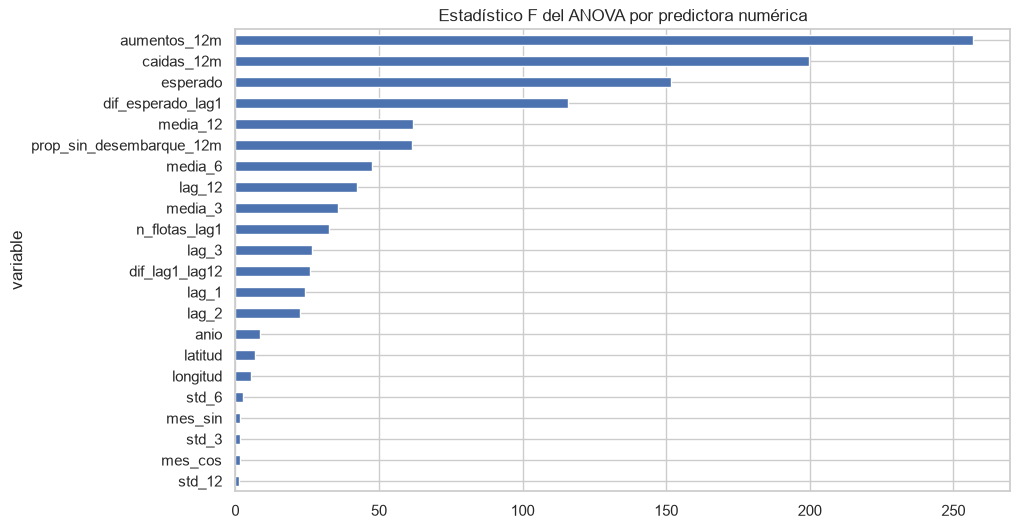

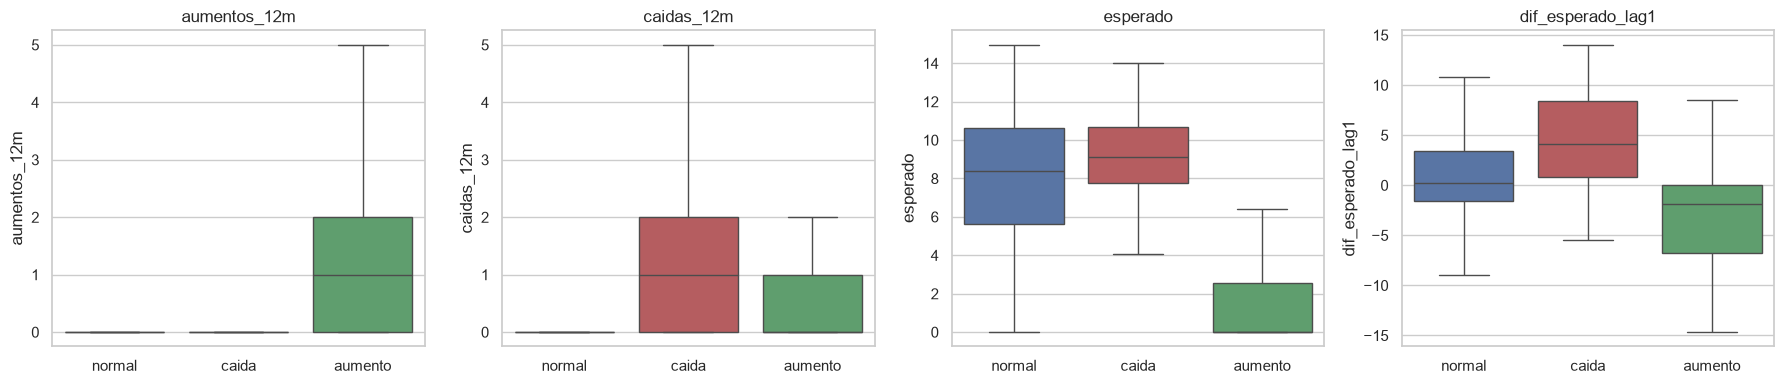

In [32]:
# Estadístico F de cada predictora numérica y distribución por clase de las cuatro con mayor F
dep_num.F.sort_values().plot.barh(figsize=(10, 6), title="Estadístico F del ANOVA por predictora numérica"); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, dep_num.index[:4]):
    sns.boxplot(data=ent, x=TARGET, y=col, order=CLASES, hue=TARGET, hue_order=CLASES, legend=False,
                palette=["#4C72B0", "#C44E52", "#55A868"], showfliers=False, ax=a)
    a.set_title(col); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Análisis de los resultados:**

*Predictoras categóricas.* Todas tienen *p*-valor menor que 0,05, excepto `mes` (*p* = 0,63).
- `anomalia_lag1` es la de *p*-valor más chico: la clase del mes anterior se relaciona fuertemente con la del mes actual, porque las anomalías tienden a repetirse. Le siguen `puerto` y `flota_principal`.
- `mes` no se relaciona con la clase. Esto confirma que la forma de definir la variable objetivo (comparar con el mismo mes de años anteriores) elimina la estacionalidad.
- En `anomalia_lag1`, `puerto`, `flota_principal` y `especie_agrupada`, entre el 27 % y el 36 % de las celdas tienen frecuencia esperada menor que 5, por las pocas anomalías en algunos niveles. No se cumple del todo el supuesto, pero como los *p*-valores son muy chicos (menores que 10⁻⁶), la conclusión no cambia.

*Predictoras numéricas.* Tienen *p*-valor menor que 0,05 todas excepto los desvíos móviles (`std_3`, `std_6`, `std_12`) y el mes codificado (`mes_sin`, `mes_cos`). Las de mayor F son `aumentos_12m`, `caidas_12m`, `esperado` y `dif_esperado_lag1`, y sus medias muestran diferencias claras entre caídas y aumentos:
- Antes de un aumento hubo en promedio 1,35 aumentos en los 12 meses previos (0,13 antes de un mes normal). Antes de una caída hubo 1,21 caídas (0,24 antes de un mes normal). Cada tipo de anomalía suele estar precedido por anomalías del mismo tipo.
- `esperado` vale 9,05 en las caídas y 1,68 en los aumentos (7,63 en los normales). Las caídas ocurren donde se espera una captura alta y los aumentos, donde lo habitual es una captura casi nula.
- `dif_esperado_lag1` es +4,38 antes de una caída y −3,18 antes de un aumento.

Estas variables se mueven en sentidos opuestos según el tipo de anomalía. Con una etiqueta binaria se compensarían: por ejemplo, la media de `dif_esperado_lag1` en la clase "anómala" sería 1,38, casi igual a la de los meses normales (0,94), y la variable parecería no servir. Esto confirma la conveniencia de usar tres clases.

Las medias móviles y los rezagos son más bajos antes de cualquier anomalía (entre 4,2 y 5,1, frente a 6,7–6,8 en los normales): las series con poca actividad tienen más anomalías. `anio`, `latitud` y `longitud` son significativas pero sus medias casi no cambian entre clases, por lo que su relación es débil.

### 4.5 Selección de variables

Se conservan las predictoras con *p*-valor menor que 0,05 en la sección 4.4. Luego se revisa si alguna numérica es redundante con otra: si dos variables miden casi lo mismo, la segunda no agrega información. Para eso se usa la correlación de Pearson entre las predictoras numéricas; en los pares con |*r*| > 0,90 se conserva la de mayor F.

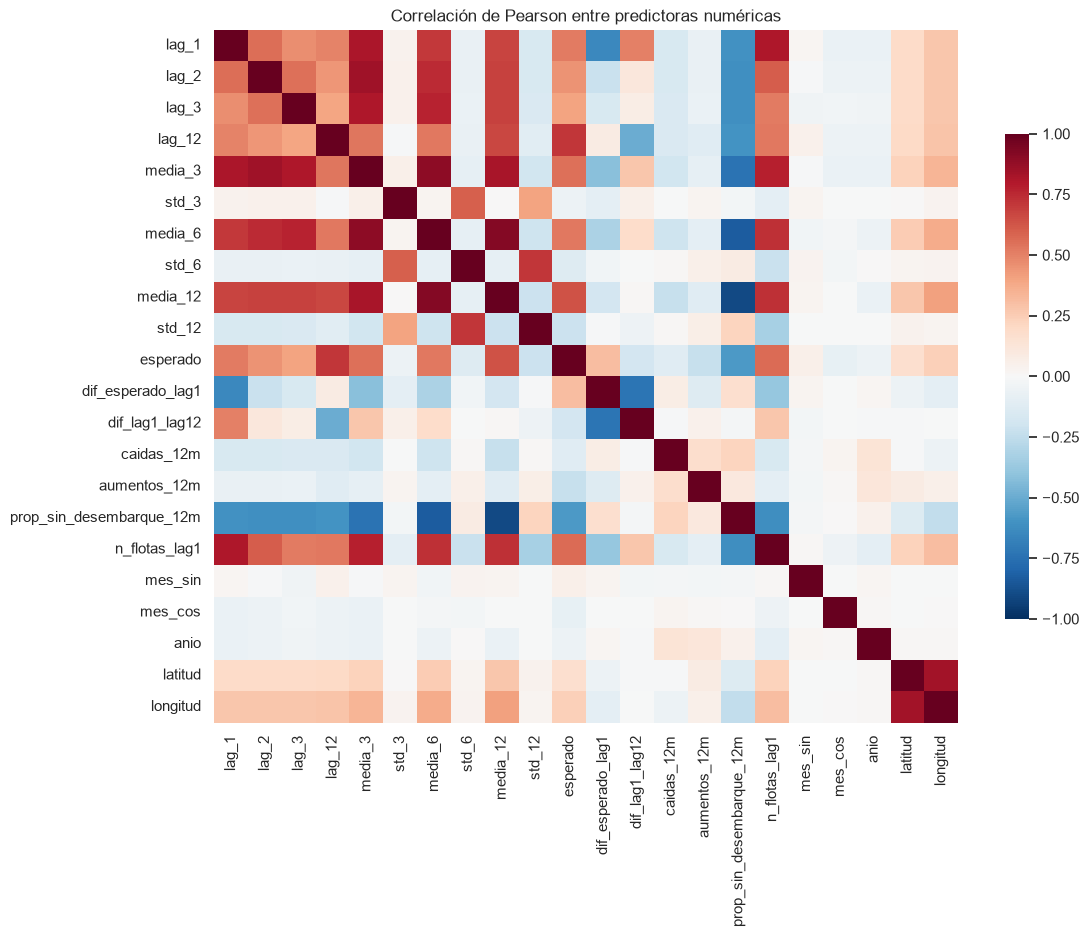

Numéricas no significativas: ['std_3', 'std_6', 'std_12', 'mes_sin', 'mes_cos']
Numéricas redundantes: {'prop_sin_desembarque_12m': 'con media_12 (r = -0.90)', 'media_6': 'con media_12 (r = 0.92)'}
Categóricas no significativas: []

Seleccionadas (21):
  numéricas: ['aumentos_12m', 'caidas_12m', 'esperado', 'dif_esperado_lag1', 'media_12', 'lag_12', 'media_3', 'n_flotas_lag1', 'lag_3', 'dif_lag1_lag12', 'lag_1', 'lag_2', 'anio', 'latitud', 'longitud']
  categóricas: ['anomalia_lag1', 'puerto', 'flota_principal', 'categoria', 'especie_agrupada', 'provincia']


In [33]:
# Correlación de Pearson entre predictoras numéricas y selección final de variables
corr = ent[FEATURES_NUM].corr(method="pearson")
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": .7})
plt.title("Correlación de Pearson entre predictoras numéricas"); plt.show()

sig_num = dep_num[dep_num.p_valor < 0.05].index.tolist()
SEL_CAT = dep_cat[dep_cat.p_valor < 0.05].index.drop("mes", errors="ignore").tolist()
redundantes = {}
for i, a in enumerate(sig_num):
    for b in sig_num[i + 1:]:
        if a not in redundantes and b not in redundantes and abs(corr.loc[a, b]) > 0.90:
            redundantes[b] = a
SEL_NUM = [c for c in sig_num if c not in redundantes]

print("Numéricas no significativas:", [c for c in FEATURES_NUM if c not in sig_num])
print("Numéricas redundantes:", {k: f"con {v} (r = {corr.loc[k, v]:.2f})" for k, v in redundantes.items()})
print("Categóricas no significativas:", [c for c in FEATURES_CAT if c not in SEL_CAT])
print(f"\nSeleccionadas ({len(SEL_NUM) + len(SEL_CAT)}):\n  numéricas: {SEL_NUM}\n  categóricas: {SEL_CAT}")

**Resultado de la selección:**
- Se descartan 5 numéricas por no ser significativas (`std_3`, `std_6`, `std_12`, `mes_sin`, `mes_cos`) y 2 por redundantes: `media_6` (*r* = 0,92 con `media_12`) y `prop_sin_desembarque_12m` (*r* = −0,90 con `media_12`). En una serie con muchos meses sin desembarque, la media de 12 meses es baja, por eso están tan correlacionadas. Se conserva `media_12`, que tiene mayor F.
- Las 6 categóricas son significativas y se conservan. `mes` no se usa como predictora.
- Quedan **21 predictoras**: 15 numéricas y 6 categóricas.

Las pruebas evalúan cada variable por separado. En la sección 7, la importancia por permutación muestra qué variables usa realmente el modelo cuando se combinan.

## 5. Descripción del dataset luego de la limpieza y el preprocesamiento

In [34]:
# Dimensiones, período, cantidad de series y distribución de la variable objetivo del dataset final
print(f"Dimensiones: {df_limpio.shape[0]:,} filas x {df_limpio.shape[1]} columnas")
print(f"Período etiquetado: {df_limpio.fecha.min():%Y-%m} a {df_limpio.fecha.max():%Y-%m}")
print(f"Series especie–puerto: {df_limpio.groupby(['especie', 'puerto']).ngroups:,}")
print(f"Especies: {df_limpio.especie.nunique()} | Puertos: {df_limpio.puerto.nunique()} | Flotas principales: {df_limpio.flota_principal.nunique()}")
print("\nDistribución de la variable objetivo:")
print(df_limpio[TARGET].value_counts().reindex(CLASES).to_frame("n").assign(proporcion=lambda d: (d.n / d.n.sum()).round(3)))
print("\nFaltantes por columna:")
f = df_limpio.isna().sum(); print(f[f > 0])

Dimensiones: 11,165 filas x 35 columnas
Período etiquetado: 2014-01 a 2018-12
Series especie–puerto: 198
Especies: 61 | Puertos: 16 | Flotas principales: 8

Distribución de la variable objetivo:
              n  proporcion
anomalia                   
normal    10546        0.94
caida       373        0.03
aumento     246        0.02

Faltantes por columna:
anomalia_lag1    198
caidas_12m       198
aumentos_12m     198
dtype: int64


In [35]:
# Diccionario de variables con el tipo y el rol de cada una
diccionario = pd.DataFrame({
    "variable": df_limpio.columns,
    "tipo": df_limpio.dtypes.astype(str).values,
    "rol": ["clave" if c in ("fecha", "especie", "puerto") else
            "objetivo (normal / caida / aumento)" if c == TARGET else
            "auxiliar (no usar como predictora)" if c in ("captura", "log_captura", "z") else
            "predictora seleccionada" if c in SEL_NUM + SEL_CAT else
            "predictora descartada (4.5)" for c in df_limpio.columns],
})
diccionario

,variable,tipo,rol
0,fecha,datetime64[us],clave
1,especie,str,clave
2,puerto,str,clave
3,categoria,str,predictora seleccionada
4,especie_agrupada,str,predictora seleccionada
5,provincia,str,predictora seleccionada
6,flota_principal,str,predictora seleccionada
7,captura,float64,auxiliar (no usar como predictora)
8,log_captura,float64,auxiliar (no usar como predictora)
9,z,float64,auxiliar (no usar como predictora)


In [36]:
# Estadísticas descriptivas de las predictoras numéricas
df_limpio[FEATURES_NUM].describe().T

,count,mean,std,min,25%,50%,75%,max
lag_1,"11,165.00",6.47,5.01,0.00,0.00,7.27,10.44,17.21
lag_2,"11,165.00",6.46,5.02,0.00,0.00,7.27,10.45,17.21
lag_3,"11,165.00",6.46,5.01,0.00,0.00,7.26,10.45,17.21
lag_12,"11,165.00",6.71,4.96,0.00,0.00,7.55,10.62,17.14
media_3,"11,165.00",6.46,4.16,0.00,3.01,6.86,9.70,15.98
std_3,"11,165.00",2.72,2.09,0.00,1.02,2.45,4.17,9.44
media_6,"11,165.00",6.47,3.74,0.00,3.56,6.54,9.27,14.93
std_6,"11,165.00",3.25,1.66,0.00,2.07,3.24,4.46,8.66
media_12,"11,165.00",6.54,3.42,0.00,3.87,6.47,9.03,14.11
std_12,"11,165.00",3.57,1.34,0.00,2.59,3.61,4.48,7.50


Las variables `captura`, `log_captura` y `z` se guardan para interpretar los resultados, pero no deben usarse como predictoras porque contienen el valor del mes que se quiere anticipar (la clase se obtiene directamente de `z`).

Las clases están desbalanceadas: las anomalías son pocas, como es de esperar por su definición. Esto se tiene en cuenta al elegir el modelo y las métricas.

## 6. Acceso al dataset limpio

La siguiente celda exporta el dataset limpio a CSV, lo descarga y, opcionalmente, lo guarda en Google Drive.

**Enlace al dataset limpio:** `https://drive.google.com/drive/folders/18GkGOAWwEB6ezbwMCQ4pHu1aaVPmFjiZ?usp=sharing`

In [37]:
# Exportación del dataset limpio a CSV y descarga (con GUARDAR_EN_DRIVE = True también se copia a Google Drive)
SALIDA = "desembarques_limpio_anomalias.csv"
df_limpio.to_csv(SALIDA, index=False, encoding="utf-8")
print(f"Archivo generado: {SALIDA} ({os.path.getsize(SALIDA) / 1e6:.1f} MB)")

GUARDAR_EN_DRIVE = False
try:
    from google.colab import files, drive
    if GUARDAR_EN_DRIVE:
        drive.mount("/content/drive")
        destino = "/content/drive/MyDrive/" + SALIDA
        df_limpio.to_csv(destino, index=False)
        print("Guardado en Drive:", destino)
    files.download(SALIDA)
except ImportError:
    pass

Archivo generado: desembarques_limpio_anomalias.csv (4.9 MB)


## 7. Modelo de Aprendizaje Automático a utilizar

### Elección: Gradient Boosting (`HistGradientBoostingClassifier`)

Gradient Boosting es un modelo ensamblado de tipo *boosting*: entrena muchos árboles de decisión chicos, uno después del otro, y cada árbol nuevo corrige los errores de los anteriores. La predicción final combina todos los árboles. A diferencia de Random Forest, que entrena árboles independientes y promedia sus resultados, en boosting cada árbol depende de los anteriores. Para tres clases se entrena un conjunto de árboles por clase y los resultados se convierten en probabilidades.

**Justificación:**
1. Es un problema de clasificación con tres clases y datos tabulares, para el que los modelos de boosting suelen dar los mejores resultados.
2. Los árboles capturan combinaciones entre variables (especie, puerto, mes, flota) sin tener que definirlas a mano, cosa que un modelo lineal no hace.
3. No necesita escalar las variables y acepta valores faltantes, que aparecen en los rezagos al inicio de cada serie.
4. Acepta variables categóricas directamente, sin crear una columna por cada valor (*one-hot*).
5. Permite compensar el desbalance con `class_weight="balanced"`, que da a cada caso un peso inversamente proporcional a la frecuencia de su clase.

**Líneas base.** Una línea base es un modelo más simple contra el que se compara el modelo elegido. Si el modelo elegido no la supera, su complejidad no se justifica. Usamos dos:
- Línea base trivial: predice siempre `normal` y da a cada clase una probabilidad igual a su proporción en el entrenamiento.
- Regresión logística: el modelo lineal de clasificación de la unidad 2.

**Validación:** partición temporal (entrenamiento 2014–2016, validación 2017, prueba 2018), para respetar el orden cronológico.

**Métricas:** no se usa la *accuracy*, porque un modelo que dice siempre `normal` acertaría más del 90 %. Se usan:
- *Recall* de `caida` y de `aumento`: proporción de cada tipo de anomalía que el modelo detecta.
- F1 macro: promedio del F1 de las tres clases.
- PR-AUC de `caida` y de `aumento`: área bajo la curva precisión–*recall* de cada clase (1 es perfecto). Su valor de referencia es la proporción de casos de esa clase: un modelo sin información obtiene ≈ 0,04 en caídas.
- PR-AUC de la alerta sin sentido: usa la probabilidad de anomalía, 1 − P(normal), para evaluar el modelo como detector binario (sección 1).

**Importancia por permutación:** se desordenan al azar los valores de una variable en el conjunto de validación y se mide cuánto empeora el modelo. Cuanto más empeora, más importante es esa variable.

Esta es una prueba preliminar para verificar que el planteo es viable. El ajuste de hiperparámetros y el análisis de errores quedan para la próxima entrega.

In [38]:
# Entrenamiento de la línea base trivial, la regresión logística y el Gradient Boosting con partición temporal
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer

X = df_limpio[SEL_NUM + SEL_CAT].copy()
for c in SEL_CAT:
    X[c] = X[c].astype("category")
y = df_limpio[TARGET]
anio = df_limpio.fecha.dt.year
tr, va, te = anio <= anio_fin - 2, anio == anio_fin - 1, anio == anio_fin
print(f"Entrenamiento: {tr.sum():,} | Validación: {va.sum():,} | Prueba: {te.sum():,}")

pre = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), SEL_NUM),
    (make_pipeline(SimpleImputer(strategy="constant", fill_value="sin_dato"), OneHotEncoder(handle_unknown="ignore")), SEL_CAT))
modelos = {
    "Línea base trivial": DummyClassifier(strategy="prior"),
    "Regresión logística": make_pipeline(pre, LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Gradient Boosting": HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight="balanced",
                                                        learning_rate=0.05, max_iter=400, early_stopping=True,
                                                        random_state=RANDOM_STATE),
}
for m in modelos.values():
    m.fit(X[tr], y[tr])

Entrenamiento: 6,862 | Validación: 2,293 | Prueba: 2,010


In [39]:
# Métricas de cada modelo sobre el conjunto de validación (2017)
from sklearn.metrics import average_precision_score, f1_score, recall_score, confusion_matrix

def evaluar(modelo, mask):
    P = modelo.predict_proba(X[mask])
    pred = modelo.predict(X[mask])
    clases = list(modelo.classes_)
    Y = label_binarize(y[mask], classes=clases)
    rec = recall_score(y[mask], pred, labels=["caida", "aumento"], average=None, zero_division=0)
    return {"recall caida": rec[0], "recall aumento": rec[1],
            "F1 macro": f1_score(y[mask], pred, average="macro", zero_division=0),
            "PR-AUC caida": average_precision_score(Y[:, clases.index("caida")], P[:, clases.index("caida")]),
            "PR-AUC aumento": average_precision_score(Y[:, clases.index("aumento")], P[:, clases.index("aumento")]),
            "PR-AUC alerta sin sentido": average_precision_score(y[mask] != "normal", 1 - P[:, clases.index("normal")])}

res = pd.DataFrame({n: evaluar(m, va) for n, m in modelos.items()}).T
res.round(2)

,recall caida,recall aumento,F1 macro,PR-AUC caida,PR-AUC aumento,PR-AUC alerta sin sentido
Línea base trivial,0.00,0.00,0.32,0.04,0.03,0.07
Regresión logística,0.70,0.80,0.35,0.33,0.17,0.24
Gradient Boosting,0.58,0.56,0.48,0.35,0.22,0.34


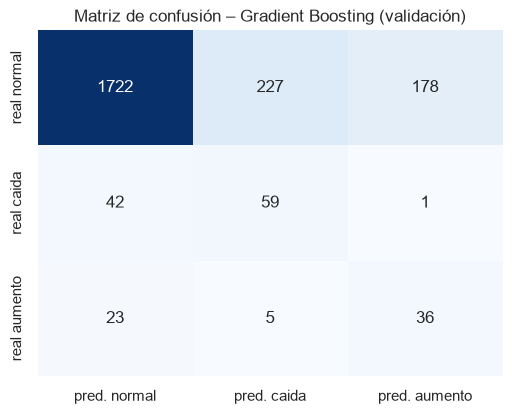

In [40]:
# Matriz de confusión del Gradient Boosting en validación
hgb = modelos["Gradient Boosting"]
cm = pd.DataFrame(confusion_matrix(y[va], hgb.predict(X[va]), labels=CLASES),
                  index=[f"real {c}" for c in CLASES], columns=[f"pred. {c}" for c in CLASES])
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusión – Gradient Boosting (validación)"); plt.show()

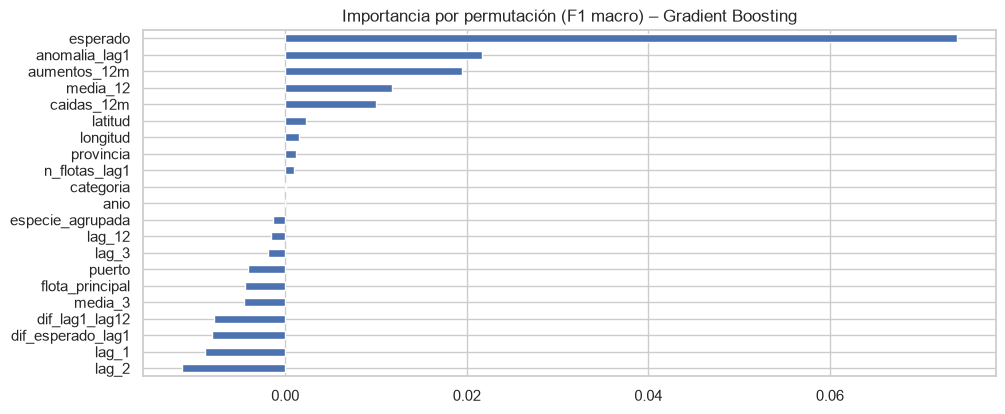

In [41]:
# Importancia por permutación de las variables del Gradient Boosting, medida con el F1 macro en validación
from sklearn.inspection import permutation_importance
imp = permutation_importance(hgb, X[va], y[va], scoring="f1_macro", n_repeats=5, random_state=RANDOM_STATE)
pd.Series(imp.importances_mean, index=X.columns).sort_values().plot.barh(
    title="Importancia por permutación (F1 macro) – Gradient Boosting"); plt.show()

**Análisis de los resultados (validación 2017):**
- **Línea base trivial.** Como predice siempre `normal`, acierta el 92,8 % de los meses de 2017, pero no detecta ninguna anomalía (*recall* 0). Su PR-AUC es igual a la proporción de cada clase (0,04 en caídas y 0,03 en aumentos).
- **Gradient Boosting frente a la línea base trivial.** Obtiene un PR-AUC de 0,35 en caídas y 0,22 en aumentos, entre 7 y 9 veces el de la línea base. Las predictoras sí permiten anticipar los dos tipos de anomalía.
- **Gradient Boosting frente a la regresión logística.** Gradient Boosting tiene mejor F1 macro (0,48 frente a 0,35) y mejor PR-AUC, sobre todo en aumentos (0,22 frente a 0,17). La regresión logística detecta más anomalías (*recall* 0,70 y 0,80), pero con muchas más falsas alarmas, como muestra su F1 más bajo.
- **Alerta sin sentido.** Usando 1 − P(normal), el Gradient Boosting obtiene un PR-AUC de 0,34 (la línea base, 0,07). Es un valor similar al del modelo binario de la entrega anterior (0,33). El modelo de tres clases sirve también como detector de anomalías sin sentido y además indica si se trata de una caída o de un aumento.
- **Matriz de confusión.** Detecta 59 de las 102 caídas y 36 de los 64 aumentos. Casi nunca confunde una caída con un aumento (6 de 166 anomalías), así que el sentido se distingue bien; lo difícil es separar las anomalías de los meses normales. Hay 405 falsas alarmas sobre 2.127 meses normales (19 %), que se pueden reducir ajustando el umbral de decisión.
- **Importancia por permutación.** Las variables más importantes son `esperado`, `anomalia_lag1`, `aumentos_12m`, `media_12` y `caidas_12m`, las mismas que en 4.4 mostraron mayor relación con la variable objetivo. Varias variables tienen importancia cercana a 0 o negativa: desordenarlas no empeora el modelo, es decir que no le aportan. Por ejemplo, `dif_esperado_lag1` se relaciona con la clase (4.4), pero su información ya está en `esperado` y `lag_1`. En la próxima entrega se probará el modelo sin esas variables.

El conjunto de prueba (2018) no se usó; queda reservado para la evaluación final.

### Próximos pasos
- Ajustar los hiperparámetros del modelo con validación temporal y los umbrales de decisión de cada clase.
- Evaluar cómo cambia la variable objetivo con otros valores de *K*, del piso de dispersión y del mínimo de historia.
- Incorporar los datos de 2019 como conjunto de prueba adicional.
- Revisar las falsas alarmas de cada clase con especialistas del dominio.